# Fraud 1 — Digital-wallet transaction review (CRISP-DM)
**Aäron Bos** — Group 5, Data Science for Business (DATDRD05-T03)

Labels used: **[Data fact]** = visible in an output · **[Assumption]** = scenario assumption, not a company fact · **[Choice]** = my analytical decision.

## Phase 1 — Business Understanding

| | |
|---|---|
| **Problem** | Fraud causes chargeback losses, but the fraud team can review only a limited number of transactions. |
| **Stakeholder / user** | Fraud analysts and their team lead (work the review queue). Also affected: legitimate customers (a review delays their payment) and finance (pays the losses). |
| **Decision** | Per transaction: send to manual review, yes/no. The model only ranks transactions; it never blocks a payment itself. |
| **Prediction moment** | When the payment is made — before any investigation. Only information known at that moment may be used. |
| **Observation unit / key / target** | One transaction · `transaction_id` · `fraud_flag` (1 = fraud). |
| **Scope** | The 12 columns of this file only; no dates, no review costs. |

**Success criterion.** Accuracy is unsuitable: fraud is rare, so "never fraud" is ≈ 99 % accurate and catches nothing. The decision is *which transactions to review within a limited capacity*, so I measure **at a capacity**:
* **Primary:** recall@5 % — share of all fraud inside the 5 % highest-scored transactions. Starting target: **≥ 50 %**.
* **Secondary:** € fraud loss caught, false alarms (legitimate customers reviewed).
* **Benchmark:** the model must beat a free rule: *"review the largest amounts first"*.

**Assumptions**
* **[Assumption]** Capacity = 5 % of transactions (≈ 160). The real number must come from the fraud team, so 2–20 % is also shown.
* **[Assumption]** A missed fraud costs `post_investigation_loss_eur`; a false alarm costs analyst time and customer friction (no € value given).
* **[Assumption]** `customer_avg_amount_30d` and `previous_transactions_24h` are computed *before* the payment. If they include it, they leak slightly — to confirm with the data owner.
* **[Assumption]** The 50 % target is my own starting point and is re-assessed in Phase 5.

## Phase 2 — Data Understanding

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('group_05_fraud_1.csv')
if not DATA.exists(): DATA = Path('group_05_fraud_1 2.csv')   # name as downloaded
df = pd.read_csv(DATA)
print(df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).head(12))
print('Exact duplicates:', df.duplicated().sum())
print('Unique transaction_ids:', df['transaction_id'].nunique(), 'of', len(df))

(3203, 12)


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
0,TX10000000,15.09,211.67,1000,2,online,UK,3,108,0,0.0,0
1,TX10000001,275.43,105.64,2266,2,online,ES,12,729,0,0.0,0
2,TX10000002,88.57,59.13,1623,3,APP,BE,19,34,0,0.0,0
3,TX10000003,8.43,9.91,1714,3,app,DE,1,65,0,0.0,0
4,TX10000004,125.85,23.86,328,3,online,BE,7,835,0,0.0,0


amount_eur                        20
transaction_id                     0
customer_avg_amount_30d            0
account_age_days                   0
previous_transactions_24h          0
channel                            0
country                            0
hour                               0
device_age_days                    0
fraud_flag                         0
post_investigation_loss_eur        0
chargeback_confirmed_after_60d     0
dtype: int64

Exact duplicates: 3
Unique transaction_ids: 3200 of 3203


**[Data fact]** 3,203 transactions × 12 columns. 20 missing `amount_eur`; 3 exact duplicate rows, which are also the 3 repeated `transaction_id`s (full copies, not different transactions).

| Column | Known at payment moment? | Role |
|---|---|---|
| `transaction_id` | yes | key only |
| `amount_eur`, `customer_avg_amount_30d`, `account_age_days`, `previous_transactions_24h`, `channel`, `country`, `hour`, `device_age_days` | yes | predictors |
| `fraud_flag` | no | **target** |
| `post_investigation_loss_eur`, `chargeback_confirmed_after_60d` | **no** — created after investigation | **leakage** |

In [2]:
print('Target:')
display(pd.DataFrame({'count': df['fraud_flag'].value_counts(),
                      'share_%': (df['fraud_flag'].value_counts(normalize=True) * 100).round(2)}))
print('fraud_flag vs chargeback_confirmed_after_60d:')
display(pd.crosstab(df['fraud_flag'], df['chargeback_confirmed_after_60d']))
print('post_investigation_loss_eur per class:')
display(df.groupby('fraud_flag')['post_investigation_loss_eur'].describe().round(2))

Target:


,count,share_%
fraud_flag,,
0,3172,99.03
1,31,0.97


fraud_flag vs chargeback_confirmed_after_60d:


chargeback_confirmed_after_60d,0,1
fraud_flag,,
0,3172,0
1,0,31


post_investigation_loss_eur per class:


,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
0,3172.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,31.0,89.63,96.38,7.82,37.44,59.95,91.94,406.81


* **[Data fact]** Only **31 frauds (0.97 %)** → severe imbalance; confirms that accuracy is useless here.
* **[Data fact]** `chargeback_confirmed_after_60d` is **identical** to the target and the loss is > 0 **only** for fraud. Both exist only after investigation → **leakage, excluded as predictors**. The loss column is kept *for evaluation in euros only* (median ≈ €60, max ≈ €407 per fraud).
* **Refines Phase 1:** the label is really "chargeback confirmed after 60 days", so true labels of new transactions arrive ≈ 2 months late (relevant for monitoring, Phase 6).

In [3]:
print('channel:', df['channel'].value_counts().to_dict())
print('country:', df['country'].value_counts().to_dict())
print('negative account_age_days:', (df['account_age_days'] < 0).sum(),
      '| negative device_age_days:', (df['device_age_days'] < 0).sum(),
      '| amount <= 0:', (df['amount_eur'] <= 0).sum())
print('fraud among missing amounts:', df.loc[df['amount_eur'].isna(), 'fraud_flag'].sum(),
      '| fraud among negative ages:', df.loc[df['account_age_days'] < 0, 'fraud_flag'].sum())
print('amount_eur: median', df['amount_eur'].median(), '| mean', round(df['amount_eur'].mean(), 1),
      '| max', df['amount_eur'].max())

channel: {'app': 1019, 'online': 1000, 'store': 596, 'Online': 246, 'APP': 230, 'ONLINE': 112}
country: {'DE': 569, 'UK': 544, 'NL': 534, 'BE': 522, 'FR': 519, 'ES': 515}
negative account_age_days: 4 | negative device_age_days: 0 | amount <= 0: 0
fraud among missing amounts: 0 | fraud among negative ages: 0
amount_eur: median 60.38 | mean 97.0 | max 1895.47


* **[Data fact]** `channel` has 6 spellings for 3 channels (`app/APP`, `online/Online/ONLINE`, `store`). Countries are clean.
* **[Data fact]** 4 negative account ages (impossible). Neither these nor the missing amounts contain fraud.
* **[Data fact]** Amounts are strongly right-skewed (median €60, max €1,895). The large amounts are plausible payments, not errors, so they are kept; I compare classes with medians.

fraud_flag,legit,fraud
amount_eur,60.4,70.4
customer_avg_amount_30d,48.2,35.2
account_age_days,1249.0,1404.0
previous_transactions_24h,2.0,2.0
hour,12.0,7.0
device_age_days,604.0,717.0


Median amount / own 30-day average: {0: 1.26, 1: 2.18}


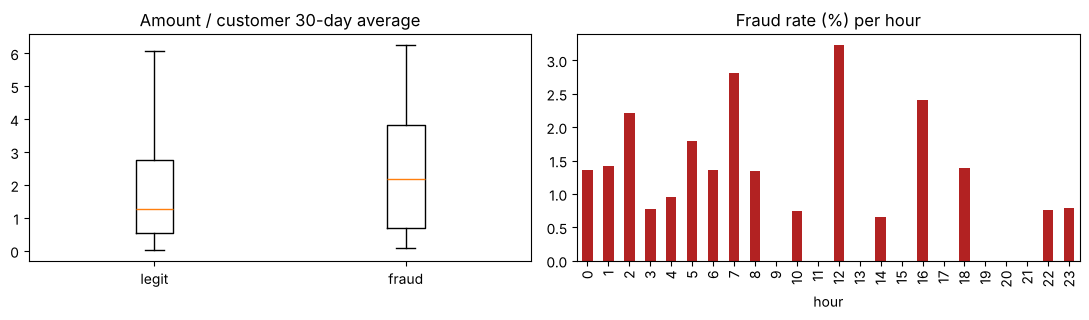

In [4]:
num_cols = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days',
            'previous_transactions_24h', 'hour', 'device_age_days']
display(df.groupby('fraud_flag')[num_cols].median().T.round(1).rename(columns={0: 'legit', 1: 'fraud'}))

ratio = df['amount_eur'] / df['customer_avg_amount_30d']
print('Median amount / own 30-day average:', ratio.groupby(df['fraud_flag']).median().round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].boxplot([ratio[df.fraud_flag == 0].dropna(), ratio[df.fraud_flag == 1].dropna()], showfliers=False)
ax[0].set_xticks([1, 2], ['legit', 'fraud']); ax[0].set_title('Amount / customer 30-day average')
(df.groupby('hour')['fraud_flag'].mean() * 100).plot.bar(ax=ax[1], color='firebrick')
ax[1].set_title('Fraud rate (%) per hour'); ax[1].set_xlabel('hour')
plt.tight_layout(); plt.show()

* **[Data fact]** Absolute amounts differ little (median €70 vs €60), but fraud is **≈ 2.2× the customer's own 30-day average vs ≈ 1.3× for legit**. Fraud looks like *unusual for this customer*, not *large in general*.
* **[Data fact]** Fraud happens earlier in the day (median hour 7 vs 12); the hourly chart shows higher fraud rates in the night/early-morning hours.
* **[Data fact]** Account age and device age are *not* lower for fraud, so the common "new account / new device" assumption is **not supported** here.

**Findings:** (1) rare target with two perfect leakage columns; (2) the clearest signal is relative amount and time of day — all other separation is weak.
**Limitations:** (1) only 31 frauds → one extra fraud caught moves recall by ≈ 3 points, so every metric is unstable; (2) no timestamp → no time-based validation, drift cannot be checked; review costs and capacity are unknown.
**Effect on Phase 1:** framing confirmed; the 50 % target already looks optimistic given these weak signals.

## Phase 3 — Data Preparation
**[Choice]** Steps that learn nothing from the data are done here. Steps that *learn* (median imputation, scaling, one-hot encoding) are put in the model pipeline (Phase 4), so they are fitted on training data only — this prevents test information leaking into training.

In [5]:
work = df.copy()

# Decision 1 — remove exact duplicates
print('BEFORE: rows', len(work), '| unique ids', work['transaction_id'].nunique(), '| fraud', work['fraud_flag'].sum())
work = work.drop_duplicates()
print('AFTER : rows', len(work), '| unique ids', work['transaction_id'].nunique(), '| fraud', work['fraud_flag'].sum())
assert work['transaction_id'].is_unique

BEFORE: rows 3203 | unique ids 3200 | fraud 31
AFTER : rows 3200 | unique ids 3200 | fraud 31


**Decision 1 — Remove duplicates.** A duplicated row counts twice in training and can land in both a training and a test fold, which inflates the evaluation. **Result:** 3,203 → 3,200 rows, key now unique, all 31 frauds kept.

In [6]:
# Decision 2 — exclude identifier and post-investigation fields
target = 'fraud_flag'
leakage_cols = ['post_investigation_loss_eur', 'chargeback_confirmed_after_60d']
excluded = [target, 'transaction_id'] + leakage_cols
loss_eur = work['post_investigation_loss_eur']          # evaluation only, never a predictor

caught_by_leak = (work.loc[work[target] == 1, 'chargeback_confirmed_after_60d'] == 1).mean()
print('Share of fraud "caught" by the chargeback column alone:', caught_by_leak)

Share of fraud "caught" by the chargeback column alone: 1.0


**Decision 2 — Exclude `transaction_id` and the two post-investigation fields.** The chargeback column alone "catches" 100 % of fraud: it *is* the answer, not a signal, and it does not exist at the payment moment. The ID is a label without behavioural meaning. **Result:** 8 behavioural predictors remain; an `assert` below guarantees no excluded column is used.

In [7]:
# Decision 3 — clean categories and impossible values
print('BEFORE channel:', work['channel'].value_counts().to_dict())
work['channel'] = work['channel'].str.strip().str.lower()
print('AFTER  channel:', work['channel'].value_counts().to_dict())

print('BEFORE negative ages:', (work['account_age_days'] < 0).sum())
work.loc[work['account_age_days'] < 0, 'account_age_days'] = np.nan
print('AFTER  negative ages:', (work['account_age_days'] < 0).sum(), '| now missing:', work['account_age_days'].isna().sum())

BEFORE channel: {'app': 1017, 'online': 999, 'store': 596, 'Online': 246, 'APP': 230, 'ONLINE': 112}
AFTER  channel: {'online': 1357, 'app': 1247, 'store': 596}
BEFORE negative ages: 4
AFTER  negative ages: 0 | now missing: 4


**Decision 3 — Standardise `channel`; impossible ages → missing.** `APP` and `app` are the same channel; keeping them apart spreads the few fraud cases over more groups and weakens the evidence. An account cannot be −22 days old; deleting the rows loses data and setting 0 invents a "brand-new" account, so I mark them missing and impute the **training** median in the pipeline (same for the 20 missing amounts). **Result:** 3 channel values; 0 negative ages.

In [8]:
# Decision 4 — feature engineering
work['amount_to_avg_ratio'] = np.log1p(work['amount_eur'] / work['customer_avg_amount_30d'])
work['is_night'] = work['hour'].between(0, 5).astype(int)

display(work.groupby(target).agg(
    median_ratio=('amount_to_avg_ratio', lambda s: np.expm1(s.median())),
    night_share_pct=('is_night', lambda s: 100 * s.mean())).round(2))

num_features = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h',
                'hour', 'device_age_days', 'amount_to_avg_ratio', 'is_night']
cat_features = ['channel', 'country']
features = num_features + cat_features
assert not set(features) & set(excluded), 'leakage column in features!'
print('Predictors:', features)

,median_ratio,night_share_pct
fraud_flag,,
0,1.26,24.01
1,2.18,35.48


Predictors: ['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'hour', 'device_age_days', 'amount_to_avg_ratio', 'is_night', 'channel', 'country']


**Decision 4 — Engineer `amount_to_avg_ratio` and `is_night`.**
* **Ratio:** €100 is normal for one customer and very unusual for another; the ratio captures *unusual for this customer*, which is how analysts reason and which a logistic regression cannot construct itself. Log-transformed because the raw ratio is extremely skewed (max ≈ 65).
* **Night flag (00–05h):** as a plain number, `hour` treats 23h and 0h as far apart. Business argument: at night the account owner is less likely to notice and react to a fraudulent payment. **Caveat:** the exact 0–5 window was chosen after looking at the hourly chart, so its strength may be slightly overstated (data snooping).
* **Result:** median ratio 2.2× (fraud) vs 1.3× (legit); night share 35 % vs 24 %. Whether these features really help is tested in Phase 4, not assumed.

| Phase 2 finding | Technique and reason | Verification | Risk | Next decision |
|---|---|---|---|---|
| 3 full duplicate rows | `drop_duplicates()` — no double counting, no row in train and test | 3,203 → 3,200, ID unique, 31 frauds | Low | Select predictors |
| Chargeback = target; loss only for fraud | Exclude both + ID; loss kept for € evaluation only | Leak column "catches" 100 %; `assert` | Hidden leakage if 30-day avg includes the payment | Clean predictors |
| 6 channel spellings; 4 negative ages; 20 missing amounts | Lower-case; negative → NaN; median imputation inside pipeline | 3 channels; 0 negatives | Imputation smooths extremes | Build features |
| Fraud = unusual for the customer, at night | Log ratio + night flag | 2.2× vs 1.3×; 35 % vs 24 % | Partly chance with 31 frauds; night window data-driven | Test with vs without in Phase 4 |

## Phase 4 — Modelling

**Validation — stratified 5-fold cross-validation [Choice].** No date column, so no chronological split. A single 30 % test set would hold only ≈ 9 frauds; one case would move recall by 11 points. With 5-fold CV every transaction is scored once by a model that **did not see it in training**, so all 31 frauds are evaluated. *Stratified* keeps ≈ 1 % fraud in every fold. Preprocessing is inside the pipeline, so it is fitted on the training folds only.

**Models**
1. **Naive "flag nothing"** — shows why accuracy misleads.
2. **Rule: largest amount first** — free and explainable; the model must beat it.
3. **Candidate: logistic regression**, `class_weight='balanced'`: simple, works on small data, gives a score to rank by, coefficients are explainable. `balanced` makes each fraud count as heavily as ≈ 100 legit transactions so fraud is not ignored. A complex model (e.g. random forest) would mainly memorise 31 cases.
4. **Same model without the engineered features** — tests Decision 4.
5. **Reduced logistic regression** (only ratio + night) — explained after the first results.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score

X, y = work[features], work[target].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # fixed seed = reproducible

def make_model(num_cols, cat_cols):
    # numeric: TRAIN median for missing values, then scaling; categorical: one-hot
    steps = [('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                               ('scale', StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols))
    return Pipeline([('prep', ColumnTransformer(steps)),
                     ('model', LogisticRegression(class_weight='balanced', max_iter=1000))])

def oof_scores(num_cols, cat_cols, cv=cv):
    # out-of-fold fraud probabilities: every row scored by a model that did not train on it
    return cross_val_predict(make_model(num_cols, cat_cols), work[num_cols + cat_cols], y,
                             cv=cv, method='predict_proba')[:, 1]

def at_capacity(score, cap):
    # review the top `cap` share of transactions with the highest score
    k = int(round(cap * len(score)))
    flagged = np.zeros(len(score), dtype=bool)
    flagged[np.argsort(-score, kind='stable')[:k]] = True
    tp = int((flagged & (y == 1)).sum())
    return {'reviews': k, 'fraud_caught': tp, 'missed_fraud': int(y.sum() - tp), 'false_alarms': k - tp,
            'recall_%': round(100 * tp / y.sum(), 1), 'precision_%': round(100 * tp / k, 1),
            'loss_caught_%': round(100 * loss_eur.values[flagged].sum() / loss_eur.sum(), 1)}

print('fraud per test fold:', [int(y[te].sum()) for _, te in cv.split(X, y)])
print('Naive "flag nothing": accuracy', round(accuracy_score(y, np.zeros_like(y)), 4), '| fraud caught 0 of', y.sum())

small_features = ['amount_to_avg_ratio', 'is_night']
base_num = [c for c in num_features if c not in small_features]
scores = {
    'Random review':                np.random.default_rng(42).random(len(y)),
    'Rule: largest amount':         work['amount_eur'].fillna(0).values,
    'LogReg without engineered':    oof_scores(base_num, cat_features),
    'LogReg candidate (all)':       oof_scores(num_features, cat_features),
    'LogReg reduced (ratio+night)': oof_scores(small_features, []),
}
display(pd.DataFrame({n: {'ROC_AUC': round(roc_auc_score(y, s), 3), 'PR_AUC': round(average_precision_score(y, s), 3),
                          **at_capacity(s, 0.05)} for n, s in scores.items()}).T)

fraud per test fold: [6, 6, 6, 6, 7]
Naive "flag nothing": accuracy 0.9903 | fraud caught 0 of 31


,ROC_AUC,PR_AUC,reviews,fraud_caught,missed_fraud,false_alarms,recall_%,precision_%,loss_caught_%
Random review,0.427,0.008,160.0,0.0,31.0,160.0,0.0,0.0,0.0
Rule: largest amount,0.556,0.012,160.0,2.0,29.0,158.0,6.5,1.2,26.3
LogReg without engineered,0.520,0.015,160.0,1.0,30.0,159.0,3.2,0.6,11.7
LogReg candidate (all),0.564,0.019,160.0,1.0,30.0,159.0,3.2,0.6,11.7
LogReg reduced (ratio+night),0.582,0.015,160.0,2.0,29.0,158.0,6.5,1.2,7.9


**Metrics.** recall@5 % = share of the 31 frauds in the top 5 %; precision@5 % = share of reviews that are fraud; loss caught = share of all fraud € in the top 5 %. ROC-AUC: 0.5 = random. PR-AUC: random ≈ fraud rate ≈ 0.01 — the more honest summary for rare events.

**Why the reduced model?** The full candidate estimates 17 coefficients from ≈ 25 frauds per training fold. A rule of thumb for logistic regression is **≈ 10 events per coefficient**, so there is room for only 2–3 predictors; more lets the model fit noise. The full model's coefficients (Phase 5) also show `amount_eur`, the 30-day average and the ratio working against each other. I therefore kept only the two features with the clearest separation in Phase 2.
**Honest caveat:** I compared both versions on the *same* data, so selecting the better one is itself a choice made with the test results in view. The reduced model's advantage is therefore probably a little optimistic; a fresh holdout or new data is needed to confirm it.

Because 31 frauds make results depend on how the folds happen to be cut, I repeat the CV with 5 different seeds:

In [10]:
rows = []
for seed in [1, 2, 3, 4, 5]:
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    for name, s in [('Rule: largest amount', scores['Rule: largest amount']),
                    ('LogReg candidate (all)', oof_scores(num_features, cat_features, cv_s)),
                    ('LogReg reduced (ratio+night)', oof_scores(small_features, [], cv_s))]:
        rows.append({'model': name, 'ROC_AUC': roc_auc_score(y, s),
                     **{f'caught@{int(c*100)}%': at_capacity(s, c)['fraud_caught'] for c in [0.05, 0.10, 0.20]}})
display(pd.DataFrame(rows).groupby('model').agg(['mean', 'min', 'max']).round(3))

ROC_AUC               caught@5%          \
                                mean    min    max      mean min max   
model                                                                  
LogReg candidate (all)         0.564  0.505  0.608       1.8   0   4   
LogReg reduced (ratio+night)   0.587  0.563  0.601       2.0   1   3   
Rule: largest amount           0.556  0.556  0.556       2.0   2   2   

                             caught@10%         caught@20%          
                                   mean min max       mean min max  
model                                                               
LogReg candidate (all)              4.4   4   5        8.6   7  10  
LogReg reduced (ratio+night)        6.2   5   8       10.8   8  12  
Rule: largest amount                4.0   4   4        5.0   5   5

* **[Data fact]** Naive model: 99 % accuracy, 0 frauds caught.
* **Noise level:** the *random* score got ROC-AUC 0.43 (expected 0.50). With 31 frauds, AUC differences of a few hundredths can be pure chance.
* **Full candidate vs rule:** ROC-AUC 0.564 vs 0.556, but at 5 % it catches 1 fraud vs the rule's 2 → **not better than the free rule**.
* **Decision 4 test:** without the engineered features ROC-AUC drops to 0.520 (≈ random) → the ratio and night flag carry most of the little signal.
* **Reduced model:** most stable over 5 seeds (ROC-AUC 0.563–0.601) and on average **2.0 / 6.2 / 10.8** frauds at 5 / 10 / 20 %, vs **2 / 4 / 5** for the rule.
* **Overall:** all approaches are only slightly better than random (PR-AUC ≈ 0.015 vs 0.0097 random). The reduced model goes to evaluation as the best candidate.

## Phase 5 — Evaluation

reviews  fraud_caught  missed_fraud  false_alarms  \
Rule: largest amount 2%      64.0           0.0          31.0          64.0   
                     5%     160.0           2.0          29.0         158.0   
                     10%    320.0           4.0          27.0         316.0   
                     20%    640.0           5.0          26.0         635.0   
LogReg reduced       2%      64.0           1.0          30.0          63.0   
                     5%     160.0           2.0          29.0         158.0   
                     10%    320.0           6.0          25.0         314.0   
                     20%    640.0          11.0          20.0         629.0   

                          recall_%  precision_%  loss_caught_%  
Rule: largest amount 2%        0.0          0.0            0.0  
                     5%        6.5          1.2           26.3  
                     10%      12.9          1.2           44.8  
                     20%      16.1          0.8           50.2  
LogReg reduced       2%        3.2          1.6            5.4  
                     5%        6.5          1.2            7.9  
                     10%      19.4          1.9           31.2  
                     20%      35.5          1.7           55.5

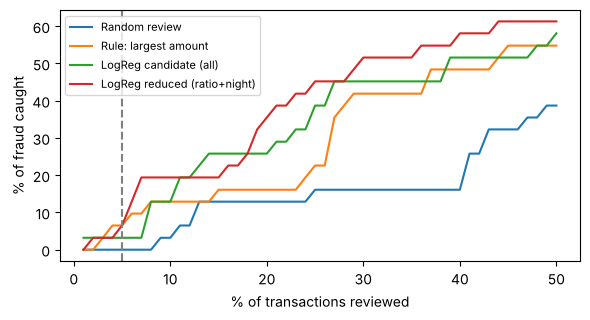

In [11]:
best = scores['LogReg reduced (ratio+night)']
rule = scores['Rule: largest amount']
caps = [0.02, 0.05, 0.10, 0.20]
display(pd.concat({n: pd.DataFrame({f'{int(c*100)}%': at_capacity(s, c) for c in caps}).T
                   for n, s in [('Rule: largest amount', rule), ('LogReg reduced', best)]}))

grid = np.linspace(0.01, 0.5, 50)
fig, ax = plt.subplots(figsize=(6, 3.3))
for n in ['Random review', 'Rule: largest amount', 'LogReg candidate (all)', 'LogReg reduced (ratio+night)']:
    ax.plot(grid * 100, [at_capacity(scores[n], c)['recall_%'] for c in grid], label=n)
ax.axvline(5, ls='--', c='grey'); ax.set_xlabel('% of transactions reviewed'); ax.set_ylabel('% of fraud caught')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Each capacity is a possible threshold. At **5 %** both the rule and the model catch 2 of 31 frauds, but the rule catches **26 %** of the fraud euros vs **8 %** for the model: the biggest frauds are large payments. From 10 % upwards the model catches more *cases* (20 %: 11 vs 5) and slightly more euros (56 % vs 50 %). Which matters more — number of victims or euros — is a business choice the scenario does not specify.

In [12]:
k = int(round(0.05 * len(y)))
flag = np.zeros(len(y), dtype=bool); flag[np.argsort(-best, kind='stable')[:k]] = True
display(pd.crosstab(pd.Series(y, name='actual fraud'), pd.Series(flag.astype(int), name='reviewed (top 5%)')))
caught = loss_eur.values[flag].sum()
print(f'Fraud loss caught: EUR {caught:,.2f} of EUR {loss_eur.sum():,.2f} | missed: EUR {loss_eur.sum()-caught:,.2f}')
print(f'False alarms per fraud found: {(flag & (y == 0)).sum() / (flag & (y == 1)).sum():.0f}')

seg = work[['channel', 'country']].assign(fraud=y, reviewed=flag, caught=flag & (y == 1))
for col in ['channel', 'country']:
    t = seg.groupby(col).agg(transactions=('fraud', 'size'), fraud=('fraud', 'sum'),
                             reviewed=('reviewed', 'sum'), caught=('caught', 'sum'))
    t['review_share_%'] = (100 * t['reviewed'] / t['transactions']).round(1)
    display(t)

full = make_model(num_features, cat_features).fit(X, y)          # fitted on all data ONLY to explain coefficients
small = make_model(small_features, []).fit(work[small_features], y)
display(pd.Series(full.named_steps['model'].coef_[0], index=full.named_steps['prep'].get_feature_names_out())
        .sort_values().round(2).to_frame('coef full model'))
display(pd.Series(small.named_steps['model'].coef_[0], index=small_features).round(2).to_frame('coef reduced'))

reviewed (top 5%),0,1
actual fraud,,
0,3011,158
1,29,2


Fraud loss caught: EUR 220.59 of EUR 2,778.46 | missed: EUR 2,557.87
False alarms per fraud found: 79


,transactions,fraud,reviewed,caught,review_share_%
channel,,,,,
app,1247,9,66,1,5.3
online,1357,14,65,1,4.8
store,596,8,29,0,4.9


,transactions,fraud,reviewed,caught,review_share_%
country,,,,,
BE,522,5,21,1,4.0
DE,569,7,32,0,5.6
ES,515,7,33,0,6.4
FR,518,4,26,0,5.0
NL,534,3,25,0,4.7
UK,542,5,23,1,4.2


,coef full model
num__amount_eur,-0.75
num__hour,-0.52
cat__channel_app,-0.37
cat__country_NL,-0.20
cat__country_FR,-0.19
cat__country_BE,-0.17
num__is_night,-0.15
cat__country_UK,-0.10
cat__channel_online,-0.07
num__account_age_days,0.12


,coef reduced
amount_to_avg_ratio,0.31
is_night,0.23


**Errors in business terms (5 %, reduced model):** 160 reviews find **2 frauds** and create **158 false alarms** — ≈ **79 legitimate customers delayed per fraud found** — while **29 frauds (≈ €2,558 of €2,778)** are still missed. A false positive costs analyst time and annoys a customer (churn risk); a false negative costs the full chargeback.

**Break-even check [Assumption].** At 5 % the model catches €221 with 160 reviews ≈ **€1.38 per review**; at 20 % ≈ €1,542 with 640 reviews ≈ **€2.41 per review**. If a review costs more (a few minutes of analyst time almost certainly does), reviewing costs more than it saves. This *overstates* the model's value: it assumes every reviewed fraud is recognised and ignores that the amount rule already catches part of these euros. The real review cost must be requested from the business.

**Segments:** reviews are spread evenly (≈ 4–6 % of transactions in every channel and country), so no group is overloaded. With 3–14 frauds per segment and 0–1 caught, **no reliable conclusion about segment performance is possible**.

**Coefficients:** in the full model, `amount_eur` (−0.75), the 30-day average (+0.37) and the ratio (+1.11) offset each other, and `is_night` gets a *negative* sign despite Phase 2 — signs of overlapping predictors and overfitting. The reduced model has the expected, explainable signs (ratio +0.31, night +0.23).

**Against Phase 1:**
| Criterion | Rule | Reduced model | Met? |
|---|---|---|---|
| ≥ 50 % fraud caught at 5 % | 6.5 % | 6.5 % | **No** |
| Clearly better than rule | — | equal at 5 %; more cases at 10–20 % | **Partly** |
| € caught at 5 % | 26 % | 8 % | Rule better |

The 50 % target is **not realistic** with these 8 variables; the realistic next goal is to prove in a pilot, on new data, that the model beats the rule.

**Limitations:** only 31 frauds; no timestamp (no test on future transactions); unknown review and friction costs; 60-day label delay; reduced model selected on the same data; unverified assumption about the 30-day average.

**Decision: do not deploy — return to Phase 1/2 and collect more data.** The model misses the success criterion, is not convincingly better than the free amount rule at 5 % capacity, and would mainly create false alarms. Keep the amount rule; retest the reduced model in shadow mode once more fraud cases and stronger pre-payment features are available.

## Phase 6 — Deployment / next iteration (design)
Because the decision is *do not deploy*, this is the design of a **shadow-mode pilot**: the model scores transactions but influences nothing until it proves itself.

| | |
|---|---|
| **User** | Fraud team lead and analysts; a data analyst maintains the model. |
| **When** | Real-time at the payment moment, using only pre-payment fields. In shadow mode scores are stored, not shown. |
| **Action** | Rank the review queue: the top-k % (k = real capacity) would be reviewed. Never blocks a payment itself. |
| **Human oversight** | Analysts decide on every reviewed case and can add/remove cases; the amount rule stays active in parallel; overrides are logged with a reason. |
| **Monitoring** | Monthly, once chargebacks arrive (≈ 60 days): recall and € caught vs the rule, false alarms per fraud found, review share per channel/country, missing-amount share and ratio distribution (drift). |
| **Refresh trigger** | Retrain at ≥ 100 new confirmed frauds, every 6 months, or when input distributions shift clearly. Outcomes return as labels, never as predictors. |
| **Go live** | Only if over ≥ 3 months it catches more fraud **and** at least as many euros as the rule at the same capacity. |
| **Pause / stop** | Recall below the rule for 2 months in a row; false alarms per fraud above the limit agreed with operations; a segment reviewed at more than twice the average rate; or a broken input (e.g. > 5 % missing amounts, new channel values). |

**Data needed:** transaction timestamps, a longer period with more fraud, review and false-alarm costs, and richer pre-payment features (device/IP change, merchant category, failed logins).

## Final decision + individual accountability
**Decision: Revisit earlier CRISP-DM phase / do not deploy yet.** The best model catches 2 of 31 frauds at 5 % capacity — equal to the free amount rule, far below the 50 % target — with ≈ 79 false alarms per fraud found, and its ROC-AUC (≈ 0.59) is close to the noise range. It only beats the rule at 20 % capacity (11 vs 5 frauds) at the cost of ≈ 630 false alarms.

**Aäron Bos**
* **Preparation choice:** I excluded the chargeback and loss columns as predictors because they only exist after investigation; the chargeback column alone "caught" 100 % of fraud. I kept the loss column only to measure euros caught.
* **Model finding:** the full logistic regression (17 coefficients, ≈ 25 frauds per fold) overfitted, with unstable and partly illogical signs. Reducing it to the ratio and night features gave more stable results and more fraud cases caught at 10–20 % capacity, though this gain needs confirmation on new data.
* **Business implication:** with this data a model mainly bothers legitimate customers without catching more fraud than the "largest amount" rule, which also protects more euros. The business should keep the rule, supply the real capacity and review costs, and collect richer data first.